# Feature Selection

Bir veri seti ve hedef verildiğinde, yalnızca hedefe katkıda bulunan özellikler makine öğrenimi sürecinde önemlidir. Alakalı olmayan özellikler, hem hesaplama kaynaklarını israf eder hem de gereksiz gürültü ekler. 

Korelasyon analizi, alakasız özellikleri ortadan kaldırmanın bir yoludur:
- Özellik veri seti sabit olmamalı veya belirli bir değişkenlik seviyesine sahip olmalıdır:
  
  Bir özellik, veri setindeki tüm özellikler için aynı değere sahipse (yani sabitse) veya çok az değişkenlik gösteriyorsa, bu özellik modele faydalı bilgi sağlamaz. Özellikler, farklı örnekler arasında değişkenlik göstermelidir ki bu model farklılıklardan öğrenebilsin

- Bir özellik hedefle ilişkili olmalı, aksi taktirde hedef tahminine katkısı olmaz:
  
  Eğer bir özellik, tahmin etmeye çalıştığımız hedef değişkenle hiçbir ilişki göstermiyorsa, bu özellik modele yararlı bilgi sağlamaz. Hedefle ilişkili özellikler, modelin daha doğru tahminler yapmasına yardımcı olur.

- Özellikler birbirleriyle yüksek derecede ilişkili olmamalı, aksi taktirde biri diğerinden fazla ek bilgi sunmaz:
  Eğer iki veya daha fazla özellik birbirleriyle çok yüsek derecede ilişkiliyse (yani yüksek korelasyon gösteriyorsa), bunlardan yalnızca birini kullanmak genellikle yeterlidir. Çünkü diğerleri aynı bilgiyi tekrar ediyor demektir. Bu durumda, fazladan özellikler sadece modele gereksiz karmaşıklık ve gürültü ekler, bu da overfitting riskini artırabilir.

Feature Selection, modelin performansını artırırken aynı zamanda hesaplama kaynaklarını da daha verimli kullanmanızı sağlar.

# Feature Extraction

Feature Extraction, makine öğrenimi için veriyi daha etkili hale getiren bir süreçtir. 

Amacı:
- Veri boyutunu küçültmek
- Daha anlamlı özellikler oluşturmak

Nasıl Çalışır?
- Orijinal özellikleri dönüştürerek yeni özellikler oluşturur.
- Bu yeni özellikler, hedef değişkenle daha güçlü bir ilişki kurar
- Veri setlerini daha kolay işlenebilir hale getirir


Yaygın yöntemler
- Doğrusal sistemler için: PCA
- Doğrusal olmayan sistemler için: Manifold tabanlı algoritmalar
- Metin ve görüntüler için: Derin öğrenme tabanlı yöntemler (CNN, RNN)

Faydaları:
- Model performansını artırır
- İşlem süresini kısaltır
- Overfittingi azaltır

Feature Extraction, veriyi sadeleştirirken önemli bilgileri korur ve modelin daha iyi öğrenmesini sağlar

# PCA - Temel Bileşen Analizi

1. PCA, karmaşık veri setlerini basitleştirmek için kullanılan bir  tekniktir.

2. Amacı:
 - Veri boyutunu azaltmak
 - En önemli bilgileri korumak
 - Verileri daha kolay anlaşılır hale getirmek

3. Nasıl çalışır:
 - Orijinal verilerdeki en önemli değişkenleri (temel bileşenleri) bulur
 - Bu bileşenler, verilerdeki değişimin çoğunu açıklar
 - Daha az önemli özellikleri eler

4. Kullanım alanları:
 - Veri görselleştirme
 - Özellik çıkarma
 - Veri sıkıştırma

5. Önemli noktalar:
 - Denetimsiz bir yöntemdir (etiketli veri gerektirmez)
 - Verileri ölçeklendirmek önemlidir
 - Sonuçta elde edilen bileşenler birbirinden bağımsızdır

In [97]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [98]:
breast_cancer_dataset = load_breast_cancer()

In [67]:
df = pd.DataFrame(breast_cancer_dataset.data, columns=breast_cancer_dataset.feature_names)
df['label'] = breast_cancer_dataset.target

In [68]:
print(df.info())
print("\nHedef değişken dağılımı:")
print(df['label'].value_counts())
print("\n0: Malign (Kötü huylu), 1: Benign (İyi huylu)")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [69]:
X = df.drop(columns='label', axis=1)
Y = df['label']

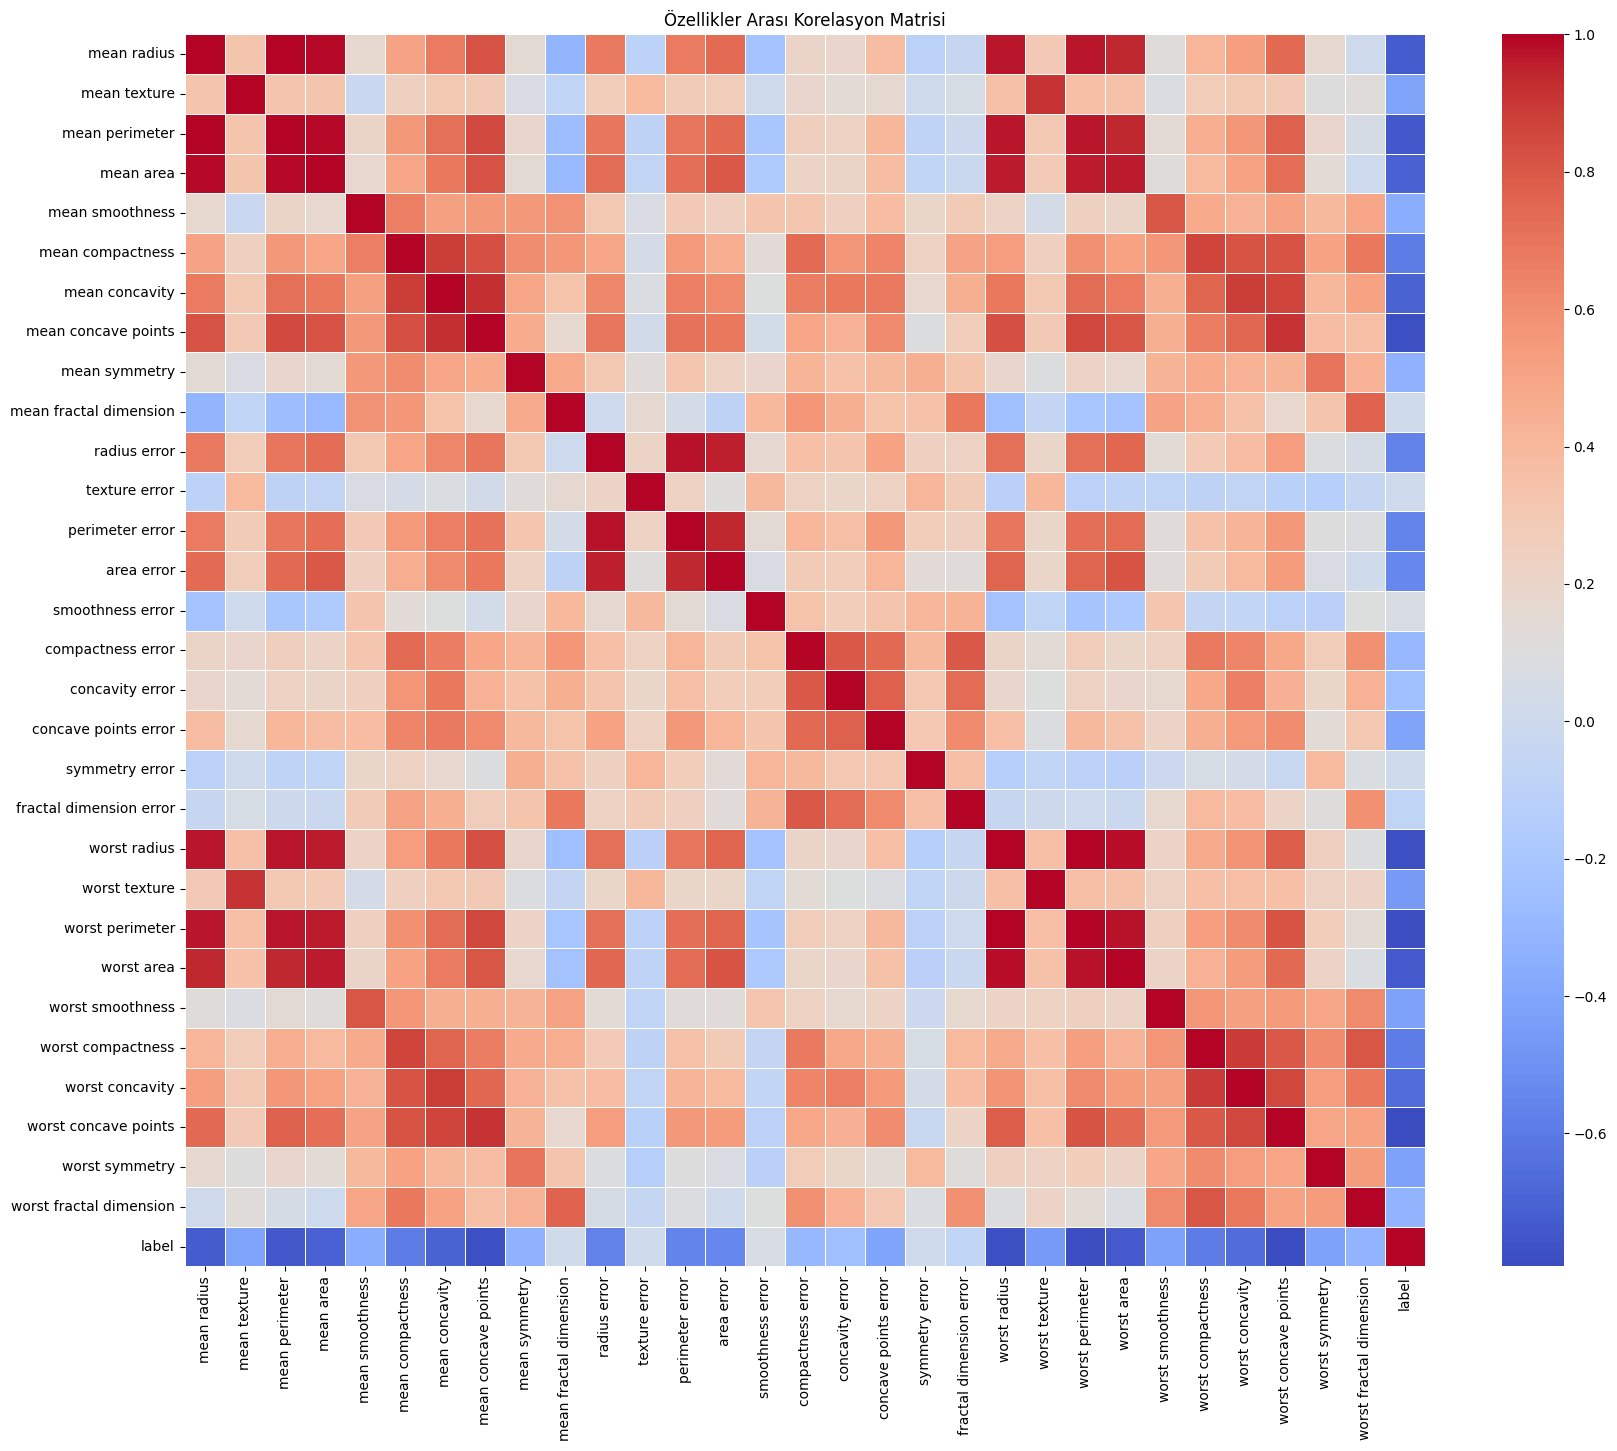

In [70]:
plt.figure(figsize=(20,16))
sns.heatmap(df.corr(), annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Özellikler Arası Korelasyon Matrisi')
plt.show()

In [71]:
selector = SelectKBest(score_func=f_classif, k='all')
selector.fit(X, Y)

SelectKBest(k='all')

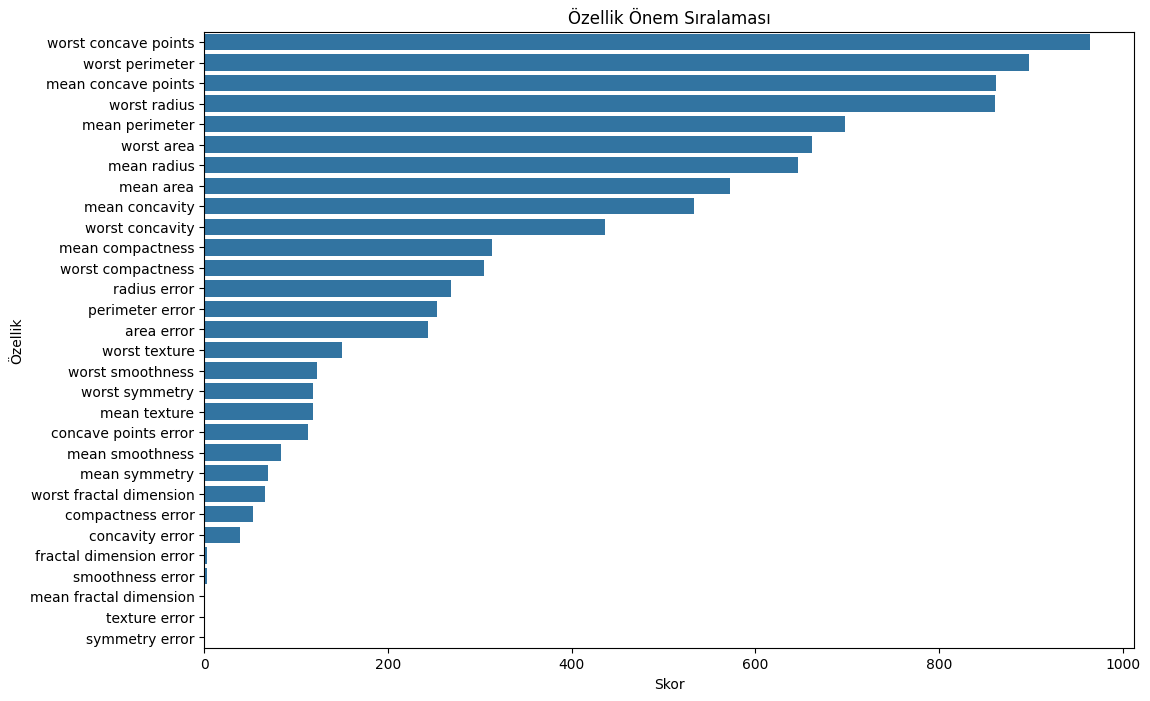

In [72]:
plt.figure(figsize=(12,8))
feature_scores = pd.DataFrame({'Özellik': X.columns, 'Skor': selector.scores_})
feature_scores = feature_scores.sort_values('Skor', ascending=False)
sns.barplot(x='Skor', y='Özellik', data=feature_scores)
plt.title('Özellik Önem Sıralaması')
plt.show()


In [99]:
k_best_features = SelectKBest(score_func=f_classif, k=20)
X_new = k_best_features.fit_transform(X, Y)

In [100]:
selected_features = X.columns[k_best_features.get_support()].tolist()
print("Seçilen en önemli 10 özellik:")
for feature in selected_features:
    print(feature)

Seçilen en önemli 10 özellik:
mean radius
mean texture
mean perimeter
mean area
mean compactness
mean concavity
mean concave points
radius error
perimeter error
area error
concave points error
worst radius
worst texture
worst perimeter
worst area
worst smoothness
worst compactness
worst concavity
worst concave points
worst symmetry


In [101]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)
X_train_new, X_test_new, Y_train, Y_test = train_test_split(X_new, Y, test_size=0.2, random_state=2)

In [102]:
model = LogisticRegression()
model.fit(X_train, Y_train)

c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [103]:
train_accuracy = model.score(X_train, Y_train)
test_accuracy = model.score(X_test, Y_test)

In [104]:
print(f"\nTüm özelliklerle model eğitim doğruluğu: {train_accuracy:.4f}")
print(f"Tüm özelliklerle model test doğruluğu: {test_accuracy:.4f}")


Tüm özelliklerle model eğitim doğruluğu: 0.9495
Tüm özelliklerle model test doğruluğu: 0.9211


In [105]:
model_new = LogisticRegression()
model_new.fit(X_train_new, Y_train)

c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [106]:
train_accuracy_new = model_new.score(X_train_new, Y_train)
test_accuracy_new = model_new.score(X_test_new, Y_test)

In [108]:
print(f"\nSeçilmiş özelliklerle yeni model eğitim doğruluğu: {train_accuracy_new:.4f}")
print(f"Seçilmiş özelliklerle yeni model test doğruluğu: {test_accuracy_new:.4f}")


Seçilmiş özelliklerle yeni model eğitim doğruluğu: 0.9538
Seçilmiş özelliklerle yeni model test doğruluğu: 0.9298


# Feature Selection

- Ne yaptık: Veri setindeki en önemli 10 özelliği seçtik
- Neden yaptık: Modelin performansını artırmak ve gereksiz özellikleri elemek için
- Sonuç: Daha az özellikle benzer veya daha iyi performans elde ettik

In [82]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [83]:
pca = PCA(n_components=0.95)  # Varyansın %95'ini koruyacak şekilde
X_pca = pca.fit_transform(X_scaled)

In [84]:
print(f"\nOrijinal özellik sayısı: {X.shape[1]}")
print(f"PCA sonrası özellik sayısı: {X_pca.shape[1]}")


Orijinal özellik sayısı: 30
PCA sonrası özellik sayısı: 10


In [85]:
# PCA ile veri setini eğitim ve test olarak bölme
X_train_pca, X_test_pca, Y_train, Y_test = train_test_split(X_pca, Y, test_size=0.2, random_state=2)

In [86]:
# PCA uygulanmış verilerle model eğitimi
model_pca = LogisticRegression()
model_pca.fit(X_train_pca, Y_train)

LogisticRegression()

In [87]:
# PCA uygulanmış verilerle model performansını değerlendirme
train_accuracy_pca = model_pca.score(X_train_pca, Y_train)
test_accuracy_pca = model_pca.score(X_test_pca, Y_test)

In [88]:
print(f"\nPCA uygulanmış verilerle model eğitim doğruluğu: {train_accuracy_pca:.4f}")
print(f"PCA uygulanmış verilerle model test doğruluğu: {test_accuracy_pca:.4f}")


PCA uygulanmış verilerle model eğitim doğruluğu: 0.9868
PCA uygulanmış verilerle model test doğruluğu: 0.9737


# Feature Extraction

- Ne yaptık: Orijinal özellikleri yeni, daha az sayıda özelliğe dönüştürdük
- Neden yaptık: Veri boyutunu azaltmak ve önemli bilgileri korumak için
- Sonuç: Daha az özellikle veri setindeki varyansın %95 ini koruduk

# PCA (Temel Bileşen Analizi)

- Ne yaptık: Verileri yeni bir koordinat sistemine dönüştürdük
- Neden yaptık: Verilerdeki en önemli değişkenliği yakalamak için
- Sonuç: Daha az sayıda özellikle verinin özünü koruduk

Bu adımlar sayesinde:

- Veri setinin boyutunu azalttık
- Gereksiz veya az önemli özellikleri eledik
- Model karmaşıklığını azalttık
- İşlem süresini kısalttık
- Overfitting riskini azalttık

Sonuç olarak daha basit ve etkili bir model elde ettik

In [89]:
# Örnek tahmin için giriş verisi
input_data = (13.54,14.36,87.46,566.3,0.09779,0.08129,0.06664,0.04781,0.1885,0.05766,0.2699,0.7886,2.058,23.56,0.008462,0.0146,0.02387,0.01315,0.0198,0.0023,15.11,19.26,99.7,711.2,0.144,0.1773,0.239,0.1288,0.2977,0.07259)

In [90]:
# Giriş verisini numpy dizisine dönüştürme
input_data_as_numpy_array = np.asarray(input_data)
input_data_reshaped = input_data_as_numpy_array.reshape(1,-1)

In [91]:
# Orijinal model ile tahmin
prediction = model.predict(input_data_reshaped)
print("\nOrijinal model ile örnek tahmin:")
if (prediction[0] == 0):
    print('Meme kanseri Malign (Kötü huylu)')
else:
    print('Meme kanseri Benign (İyi huylu)')


Orijinal model ile örnek tahmin:
Meme kanseri Benign (İyi huylu)


c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [92]:
# Yeni giriş verisini PCA ile dönüştürme
input_data_scaled = scaler.transform(input_data_reshaped)
input_data_pca = pca.transform(input_data_scaled)

c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [93]:
# PCA uygulanmış model ile tahmin
prediction_pca = model_pca.predict(input_data_pca)
print("\nPCA ile örnek tahmin:")
if (prediction_pca[0] == 0):
    print('Meme kanseri Malign (Kötü huylu)')
else:
    print('Meme kanseri Benign (İyi huylu)')


PCA ile örnek tahmin:
Meme kanseri Benign (İyi huylu)
